In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

np.random.seed(42)
%matplotlib inline

In [2]:
titanic = sns.load_dataset("titanic")
print(titanic.shape)
titanic.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("амьд үлдсэн хувь:", round(titanic["survived"].mean(), 3))
missing = titanic.isna().sum()
missing[missing > 0]

амьд үлдсэн хувь: 0.384


age            177
embarked         2
deck           688
embark_town      2
dtype: int64

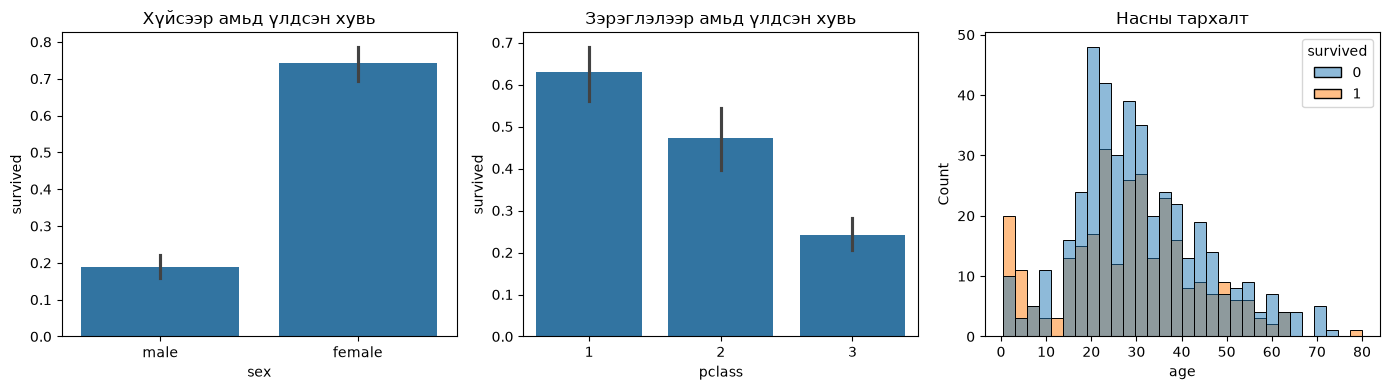

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.barplot(data=titanic, x="sex", y="survived", ax=ax[0])
sns.barplot(data=titanic, x="pclass", y="survived", ax=ax[1])
sns.histplot(data=titanic, x="age", hue="survived", bins=30, ax=ax[2])
ax[0].set_title("Хүйсээр амьд үлдсэн хувь")
ax[1].set_title("Зэрэглэлээр амьд үлдсэн хувь")
ax[2].set_title("Насны тархалт")
plt.tight_layout()
plt.show()

In [5]:
df = titanic.drop(columns=["alive", "class", "who", "adult_male", "embark_town", "deck"])
df["alone"] = df["alone"].astype(int)

X = df.drop(columns="survived")
y = df["survived"]

num_cols = ["pclass", "age", "sibsp", "parch", "fare", "alone"]
cat_cols = ["sex", "embarked"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)
print("train-ийн амьд үлдсэн хувь:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

train: (712, 8) | test: (179, 8)
train-ийн амьд үлдсэн хувь: 0.383 | test: 0.385


In [6]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

svm = Pipeline([("prep", preprocess), ("svc", SVC())])
svm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

In [7]:
no_scale = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])),
    ("svc", SVC()),
])

candidates = {
    "RBF, scale-гүй": no_scale,
    "Linear, scale-тэй": clone(svm).set_params(svc__kernel="linear"),
    "RBF, scale-тэй": clone(svm),
}
for name, m in candidates.items():
    s = cross_val_score(m, X_train, y_train, cv=5)
    print(f"{name:18s} CV acc = {s.mean():.4f} ± {s.std():.4f}")

RBF, scale-гүй     CV acc = 0.6939 ± 0.0211
Linear, scale-тэй  CV acc = 0.7922 ± 0.0177
RBF, scale-тэй     CV acc = 0.8147 ± 0.0185


In [8]:
# Pipeline дотор байгаа тул параметрийн нэр "svc__" гэж эхэлнэ
param_grid = [
    {"svc__kernel": ["rbf"],
     "svc__C": [0.1, 1, 10, 100],
     "svc__gamma": [0.01, 0.05, 0.1, 0.5]},
    {"svc__kernel": ["linear"],
     "svc__C": [0.1, 1, 10]},
]

grid = GridSearchCV(svm, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("хамгийн сайн параметр:", grid.best_params_)
print(f"CV нарийвчлал: {grid.best_score_:.4f}")

хамгийн сайн параметр: {'svc__C': 10, 'svc__gamma': 0.05, 'svc__kernel': 'rbf'}
CV нарийвчлал: 0.8245


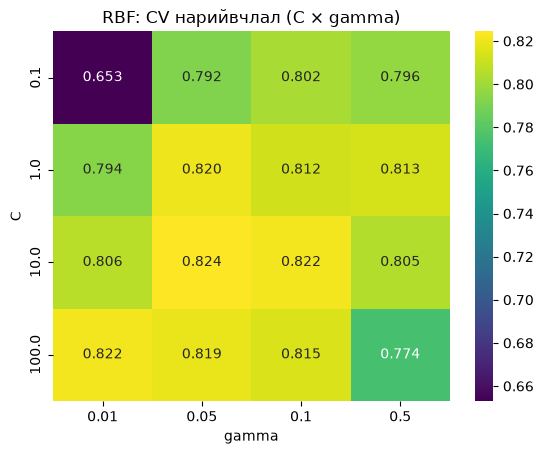

In [9]:
res = pd.DataFrame(grid.cv_results_)
if "param_svc__kernel" in res:
    res = res[res["param_svc__kernel"] == "rbf"]

if len(res) and {"param_svc__C", "param_svc__gamma"} <= set(res.columns):
    table = res.pivot_table(index="param_svc__C", columns="param_svc__gamma",
                            values="mean_test_score")
    sns.heatmap(table, annot=True, fmt=".3f", cmap="viridis")
    plt.xlabel("gamma")
    plt.ylabel("C")
    plt.title("RBF: CV нарийвчлал (C × gamma)")
    plt.show()

In [10]:
best = grid.best_estimator_
y_pred = best.predict(X_test)
names = ["нас барсан", "амьд үлдсэн"]

print(f"Тестийн нарийвчлал: {accuracy_score(y_test, y_pred):.4f}")
print("support vector-ийн тоо (анги тус бүр):", best.named_steps["svc"].n_support_)
print()
print(classification_report(y_test, y_pred, target_names=names, digits=4))

Тестийн нарийвчлал: 0.8045
support vector-ийн тоо (анги тус бүр): [149 145]

              precision    recall  f1-score   support

  нас барсан     0.8049    0.9000    0.8498       110
 амьд үлдсэн     0.8036    0.6522    0.7200        69

    accuracy                         0.8045       179
   macro avg     0.8042    0.7761    0.7849       179
weighted avg     0.8044    0.8045    0.7998       179



In [11]:
base = clone(svm).fit(X_train, y_train)
summary = pd.DataFrame({
    "загвар": ["SVC (default)", "SVC (GridSearch)"],
    "CV (train)": [cross_val_score(clone(svm), X_train, y_train, cv=5).mean(), grid.best_score_],
    "тест": [accuracy_score(y_test, base.predict(X_test)), accuracy_score(y_test, y_pred)],
}).round(4)
summary

,загвар,CV (train),тест
0,SVC (default),0.8147,0.8156
1,SVC (GridSearch),0.8245,0.8045


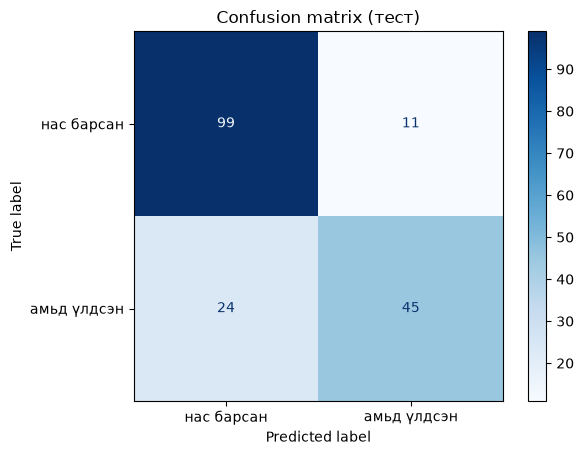

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=names, cmap="Blues")
plt.title("Confusion matrix (тест)")
plt.show()